# Где дешевле жить? Предсказание цен в Airbnb - учимся генерировать признаки и интерпретировать результаты модели

Размер исходного датасета: (48895, 16)

Первые строки:
     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   

     host_name neighbourhood_group neighbourhood  latitude  longitude  \
0         John            Brooklyn    Kensington  40.64749  -73.97237   
1     Jennifer           Manhattan       Midtown  40.75362  -73.98377   
2    Elisabeth           Manhattan        Harlem  40.80902  -73.94190   
3  LisaRoxanne            Brooklyn  Clinton Hill  40.68514  -73.95976   
4        Laura           Manhattan   East Harlem  40.79851  -73.94399   

         room_type  price  minimum_nights  number_of_reviews last_review  \
0     Pri

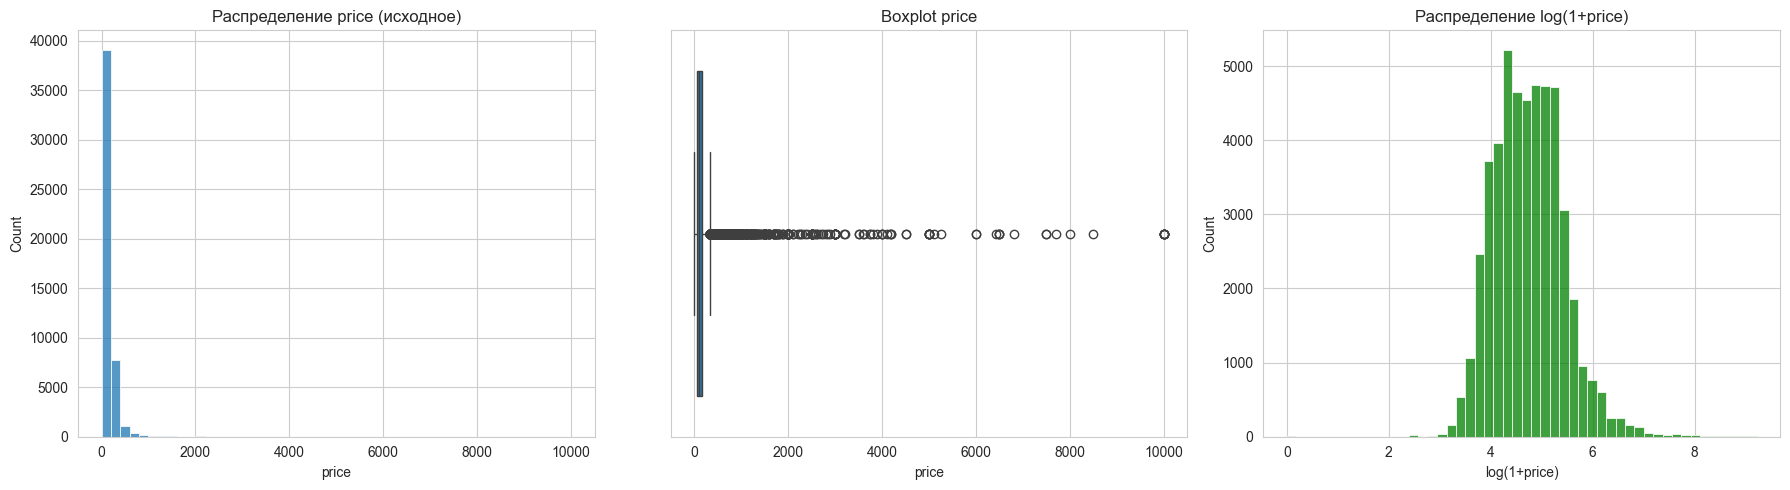

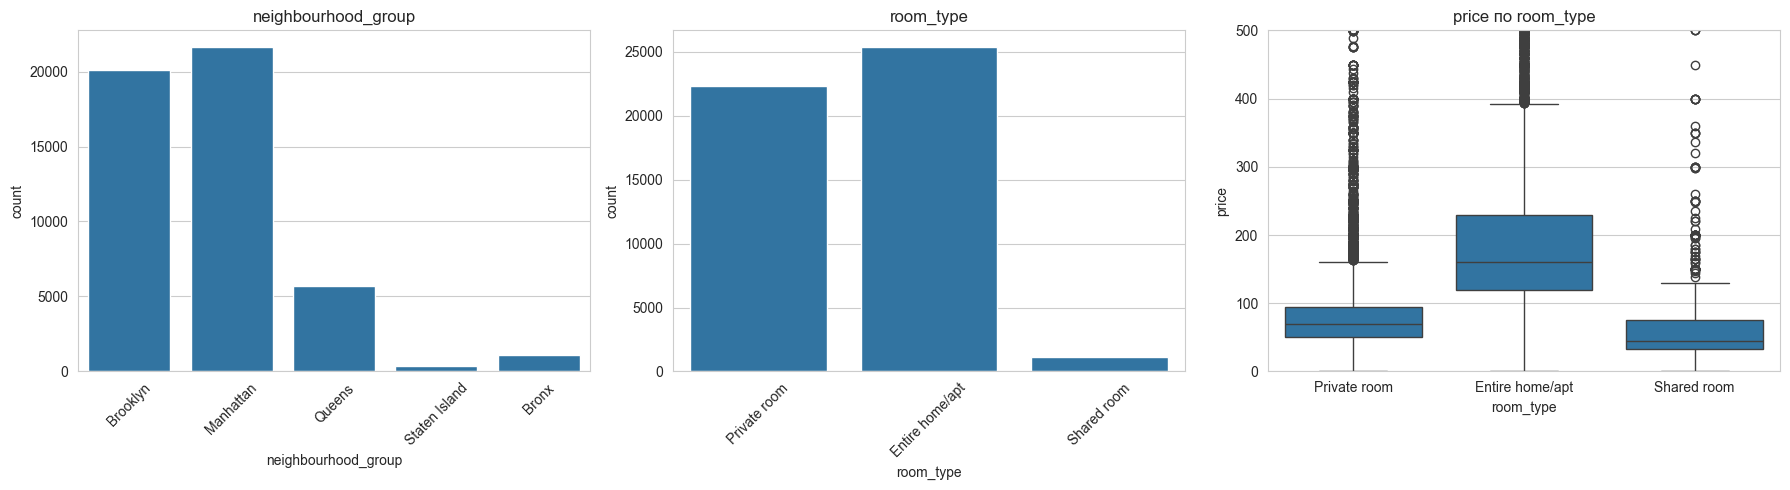

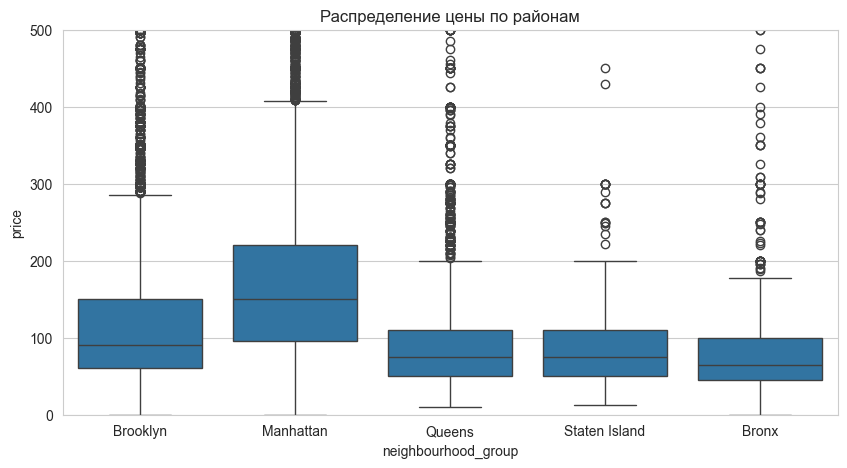

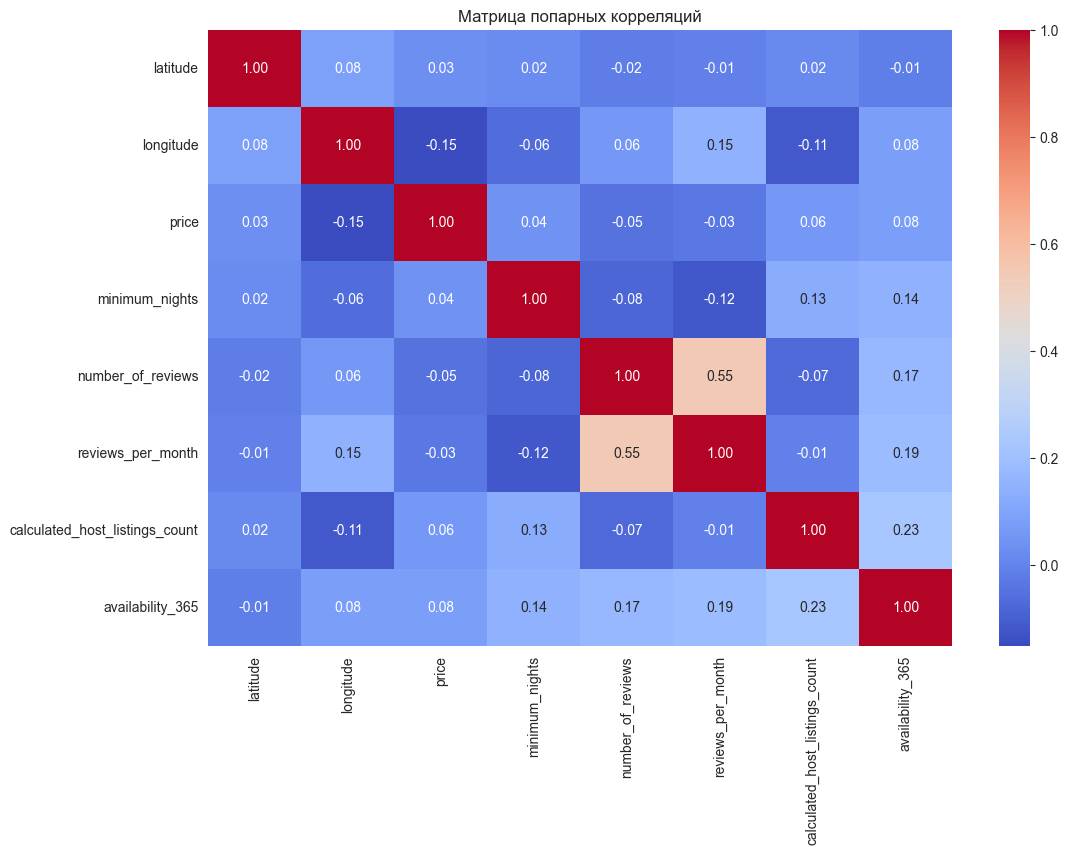

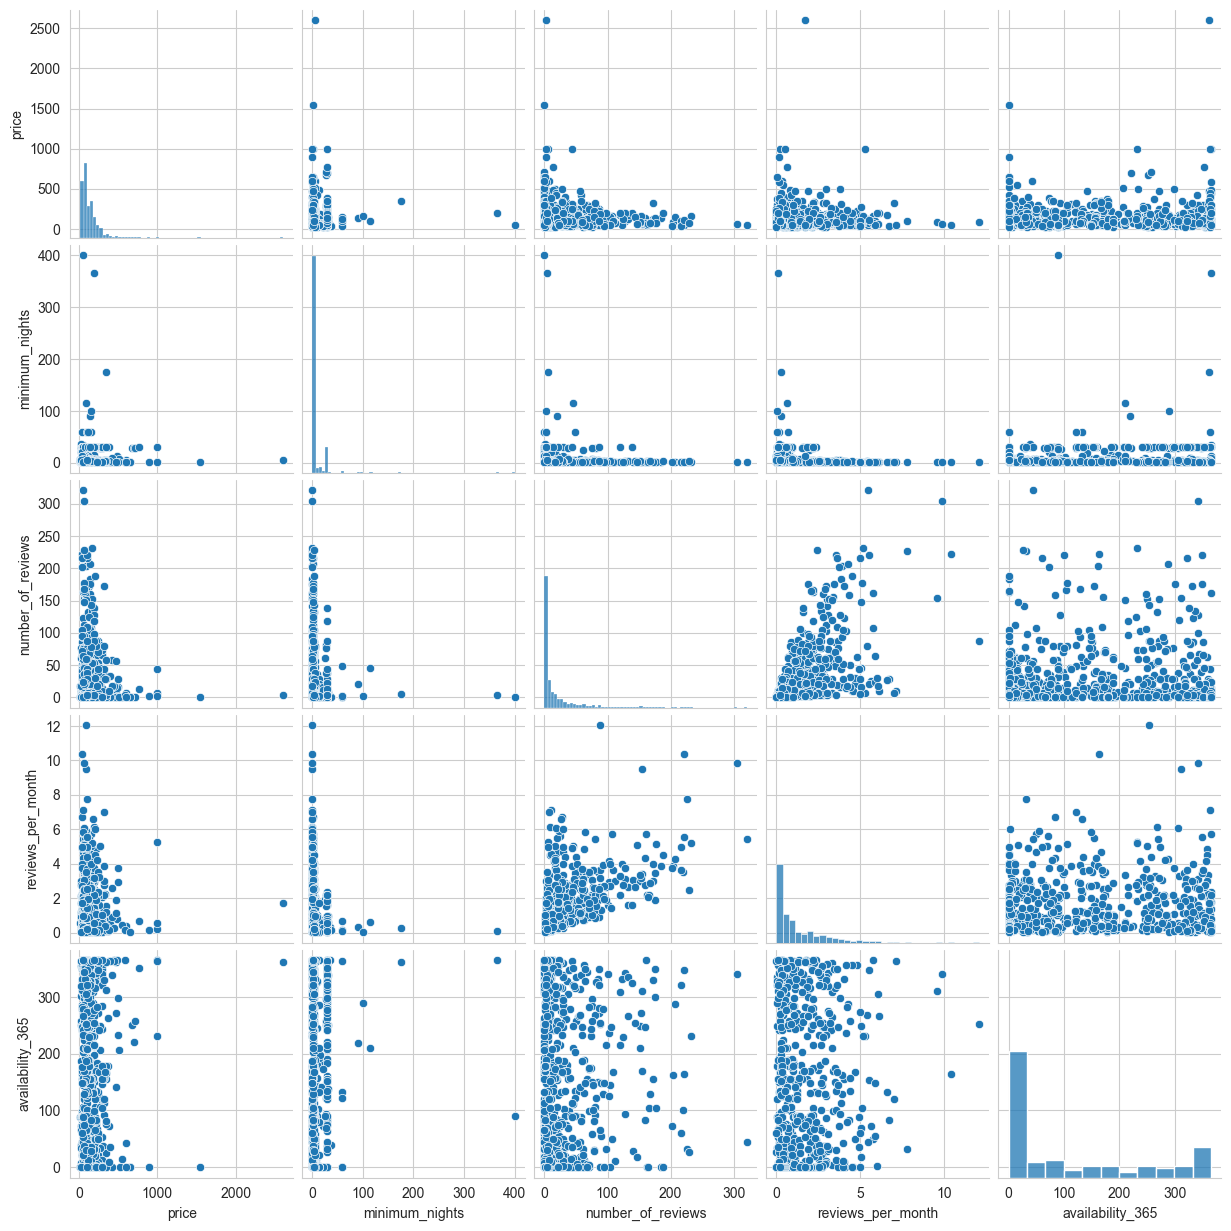

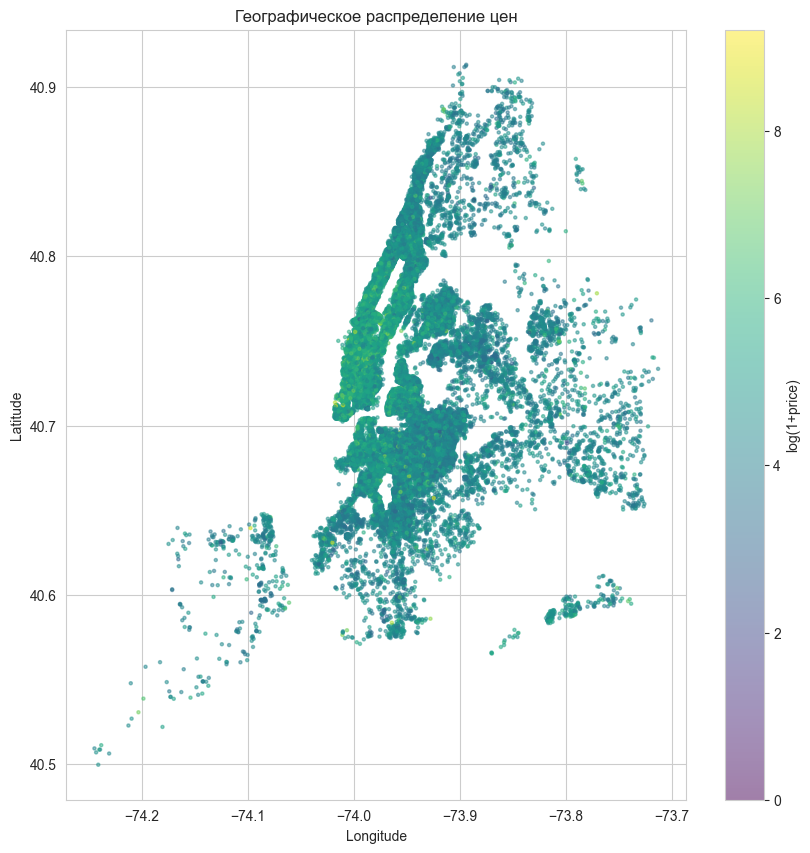

Размер после обработки пропусков: (48895, 11)
Размер после удаления аномалий: (48396, 11) (price <= 799)
Признаки после get_dummies: (48396, 15)

Новые признаки созданы. Пример:
       dist_to_manhattan  manhattan_dist  reviews_per_day  availability_ratio
count       48396.000000    48396.000000     48396.000000        48396.000000
mean            0.070717        0.091095         3.365455            0.306966
std             0.045689        0.059413        12.851609            0.359525
min             0.000717        0.001010         0.000000            0.000000
25%             0.037345        0.046397         0.009060            0.000000
50%             0.065576        0.083870         0.206443            0.120548
75%             0.091893        0.121460         1.963048            0.613699
max             0.363140        0.513550       480.000000            1.000000


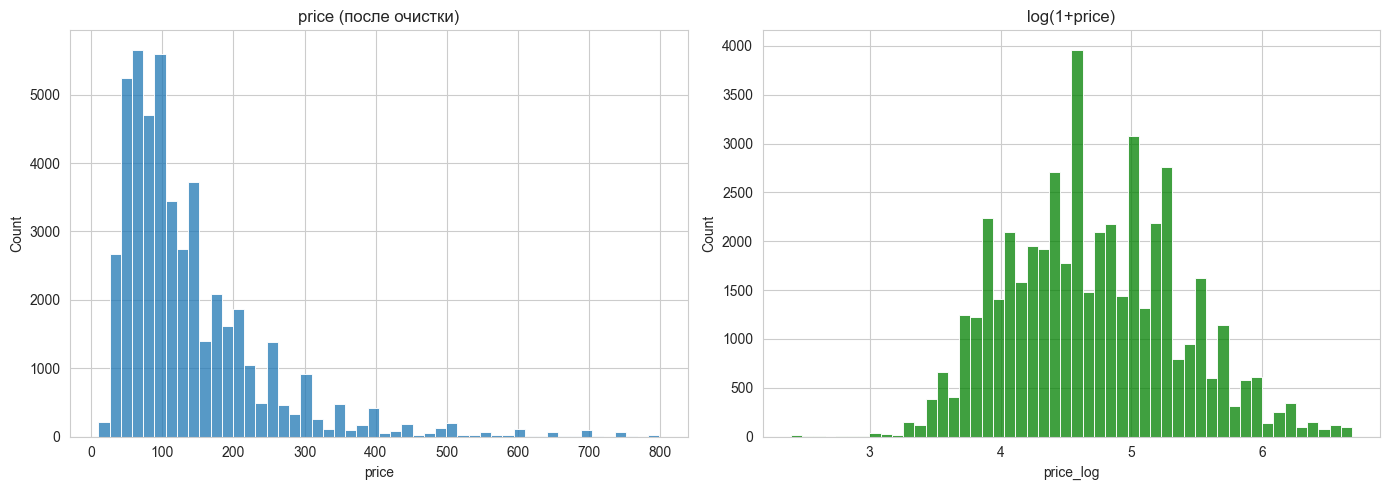

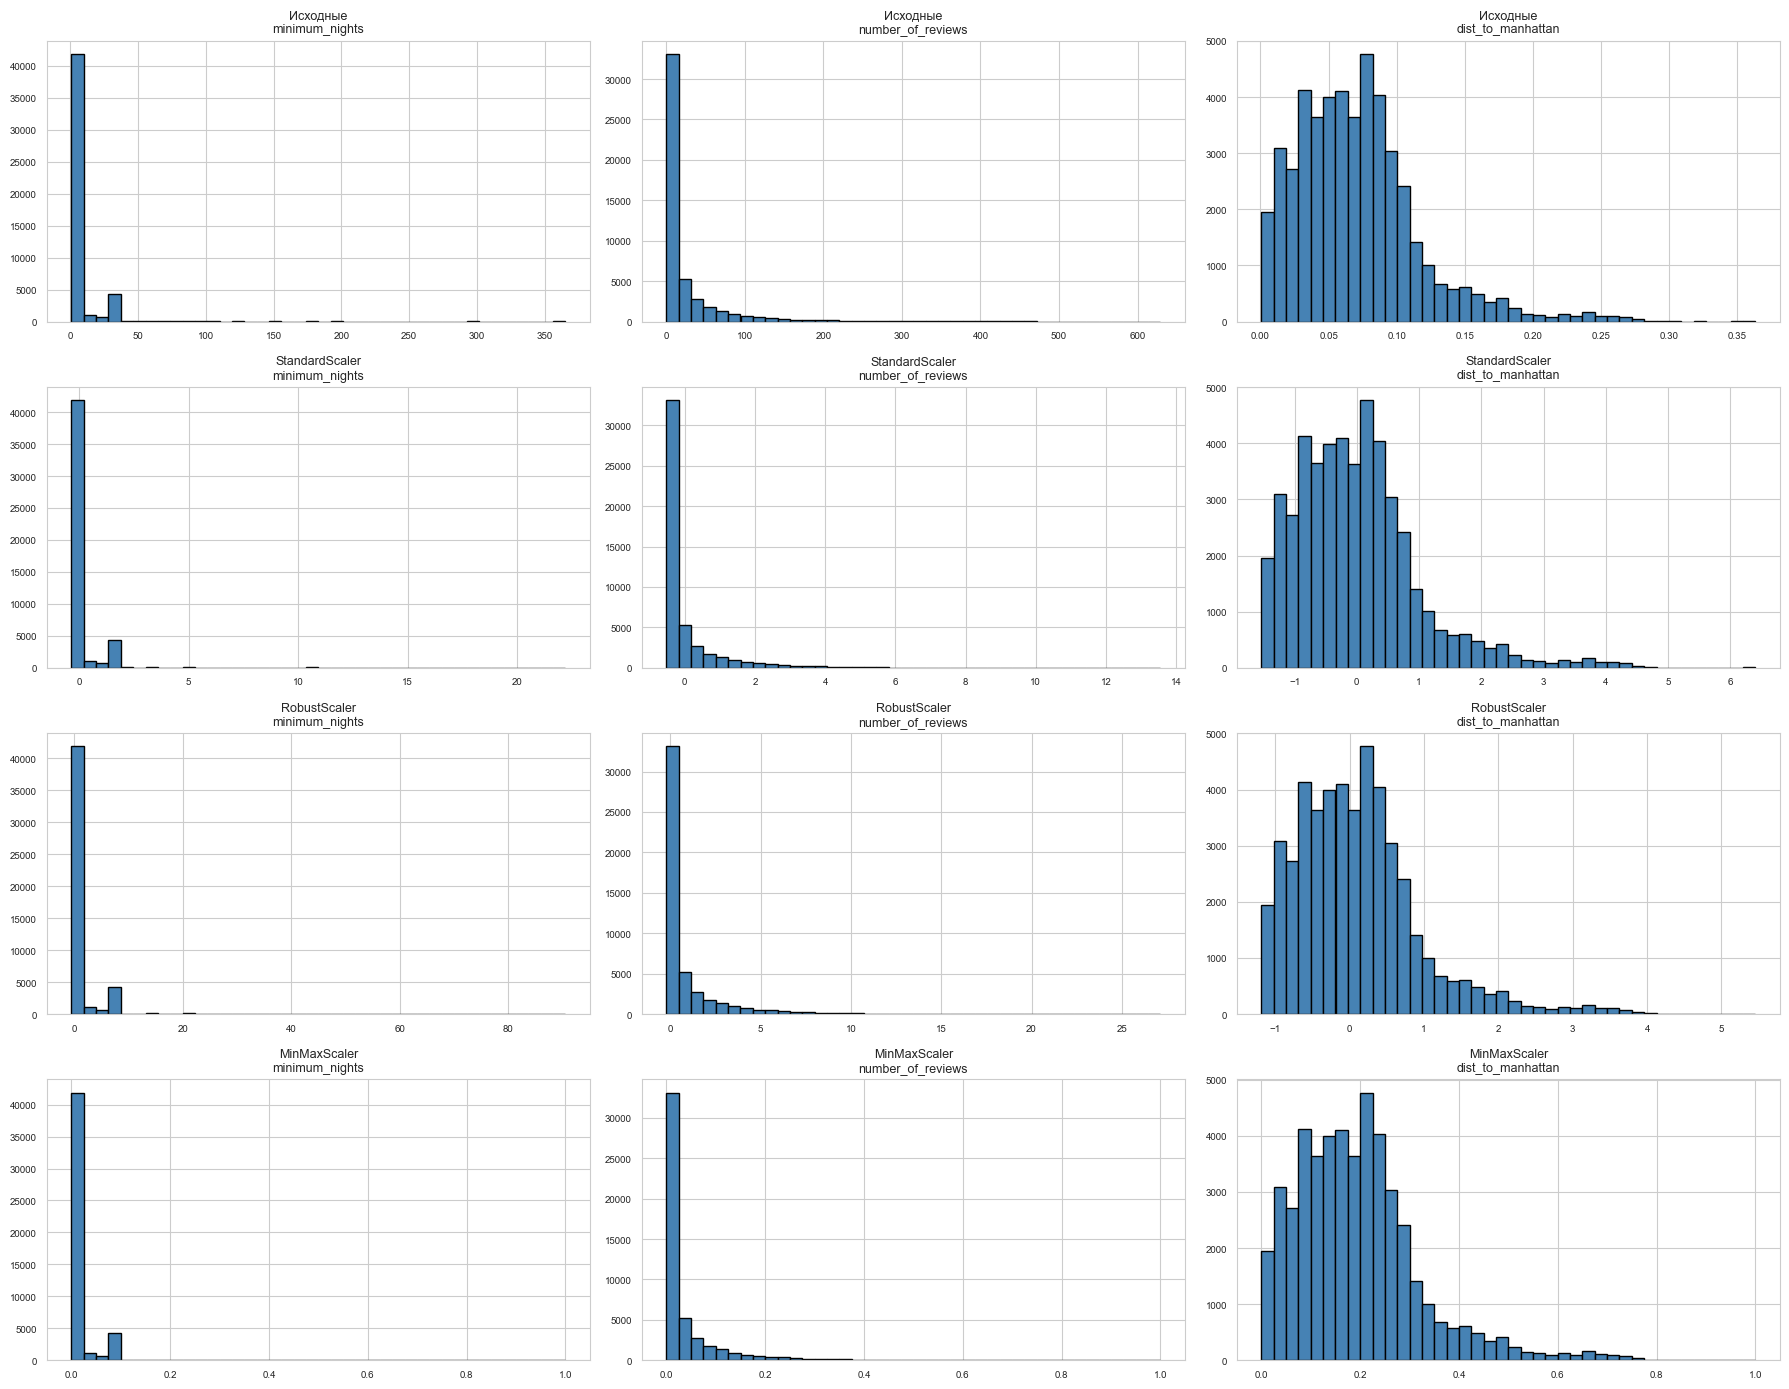


Скейлеры, которые будем сравнивать в моделях:
  - StandardScaler       (z-оценка: (x-μ)/σ)
  - RobustScaler         (x - median) / IQR — устойчив к выбросам
  - MinMaxScaler         (x - min) / (max - min) — [0, 1]
  - MaxAbsScaler         x / max(|x|) — сохраняет нули
  - QuantileTransformer  → нормальное распределение
  - PowerTransformer     Yeo-Johnson → ближе к нормальному
Форма X: (48396, 19)
Форма y: (48396,)
Признаки: ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room', 'dist_to_manhattan', 'manhattan_dist', 'dist_to_brooklyn', 'reviews_per_day', 'availability_ratio', 'is_entire']
Train: (33877, 19), Test: (14519, 19)

=== LinearRegression ===
  R2:   0.5505
  MAE:  0.3299
  RMSE: 0.4339

=== RidgeCV ===
  R2:  

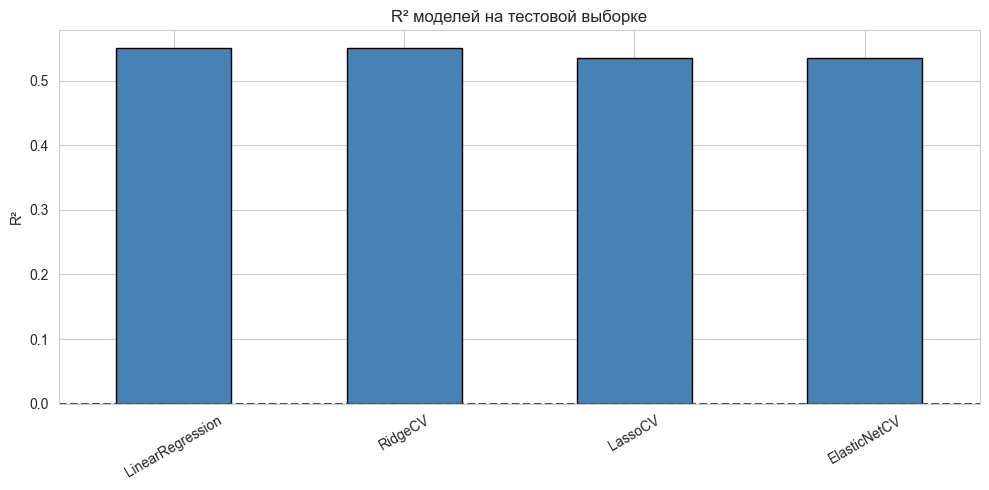

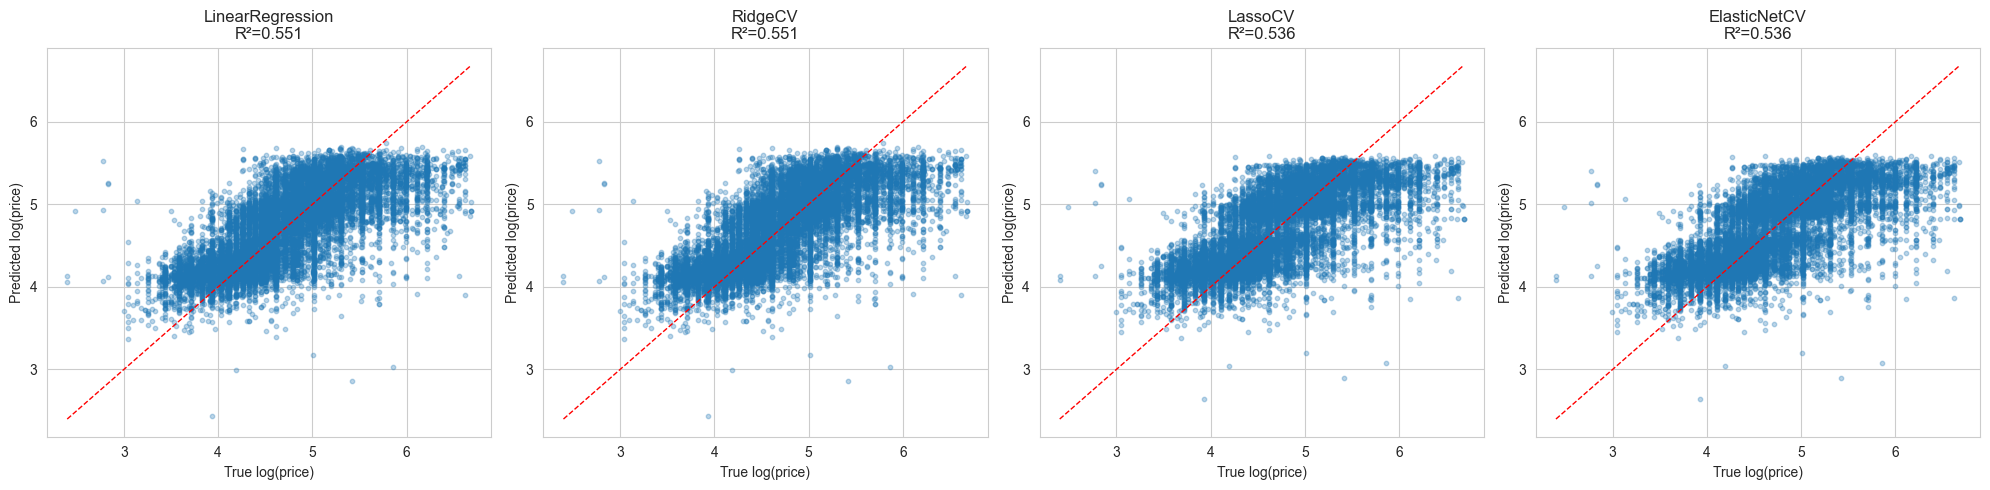

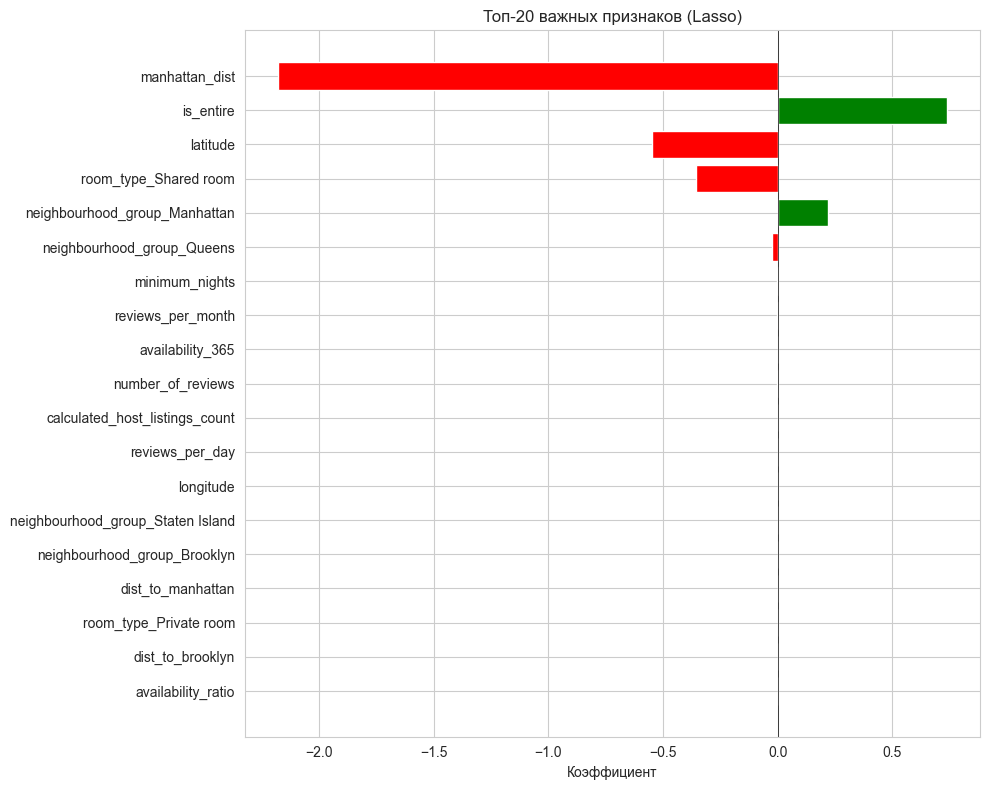


Lasso обнулил 7 из 19 признаков


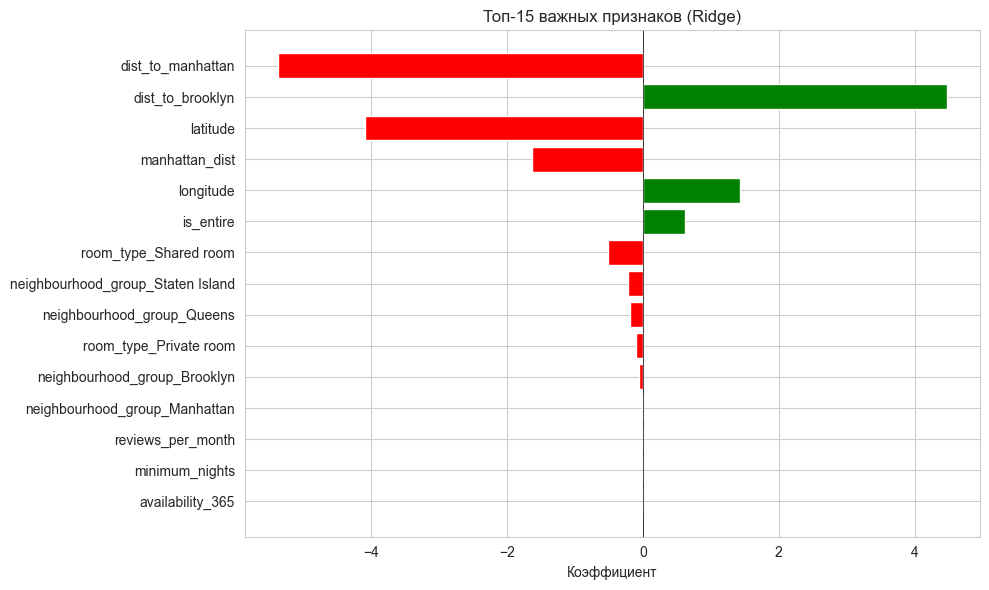


=== Сравнение: log-цель vs сырая цена (LinearRegression) ===
log(1+price):  R2=0.5505, MAE=0.3299
price:         R2=0.3733, MAE=51.8517

ИТОГОВЫЕ ВЫВОДЫ

ОПРОБОВАННЫЕ МЕТОДИКИ:

1. Логарифмирование целевой переменной (log1p) — ПОМОГЛО
   Распределение цены сильно скошено вправо, логарифм нормализует его
   и улучшает метрики линейных моделей.

2. Удаление выбросов — ПОМОГЛО
   Экстремальные значения сильно искажают коэффициенты МНК.

3. One-Hot Encoding категорий — ОБЯЗАТЕЛЬНО
   room_type и neighbourhood_group — ключевые предикторы.

4. StandardScaler — базовый вариант, работает, но чувствителен к выбросам.
   RobustScaler — ЛУЧШИЙ для наших данных: цена Airbnb и часть
  признаков (number_of_reviews, minimum_nights) содержат выбросы,
   MinMaxScaler — сжимает в [0, 1], но тоже чувствителен к выбросам.
   QuantileTransformer —  ДАЁТ БЛИЗКИЙ РЕЗУЛЬТАТ, преобразует
  распределение к нормальному, но менее интерпретируем.
  PowerTransformer (Yeo-Johnson) — ХОРОШО для скошенных признаков.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Настройки визуализации
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)

# ЧАСТЬ 1. EDA

# --- 1.1 Загрузка данных ---
df = pd.read_csv('AB_NYC_2019.csv')
print("Размер исходного датасета:", df.shape)
print("\nПервые строки:")
print(df.head())
print("\nИнформация о данных:")
print(df.info())
print("\nПропуски:")
print(df.isnull().sum())

# --- 1.2 Удаление ненужных признаков ---
drop_cols = ['id', 'name', 'host_id', 'host_name', 'last_review']
df = df.drop(columns=drop_cols, errors='ignore')
print("\nРазмер после удаления ненужных признаков:", df.shape)

# --- 1.3 Базовые статистики и распределения ---
print("\nОписательные статистики:")
print(df.describe())

# Распределение целевой переменной
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['price'], bins=50, ax=axes[0])
axes[0].set_title('Распределение price (исходное)')
axes[0].set_xlabel('price')

sns.boxplot(x=df['price'], ax=axes[1])
axes[1].set_title('Boxplot price')

sns.histplot(np.log1p(df['price']), bins=50, ax=axes[2], color='green')
axes[2].set_title('Распределение log(1+price)')
axes[2].set_xlabel('log(1+price)')
plt.tight_layout()
plt.show()

# Категориальные признаки
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='neighbourhood_group', ax=axes[0])
axes[0].set_title('neighbourhood_group')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='room_type', ax=axes[1])
axes[1].set_title('room_type')
axes[1].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='room_type', y='price', ax=axes[2])
axes[2].set_title('price по room_type')
axes[2].set_ylim(0, 500)
plt.tight_layout()
plt.show()

# Средняя цена по районам
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='neighbourhood_group', y='price')
plt.ylim(0, 500)
plt.title('Распределение цены по районам')
plt.show()


# 1.4 Матрица корреляций и pairplot
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица попарных корреляций')
plt.show()

# Pairplot на подвыборке
sample_df = df[['price', 'minimum_nights', 'number_of_reviews',
                'reviews_per_month', 'availability_365']].sample(1000, random_state=42)
sns.pairplot(sample_df)
plt.show()

# Географическое распределение цен
plt.figure(figsize=(10, 10))
scatter = plt.scatter(df['longitude'], df['latitude'],
                      c=np.log1p(df['price']), cmap='viridis',
                      s=5, alpha=0.5)
plt.colorbar(scatter, label='log(1+price)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Географическое распределение цен')
plt.show()


# ЧАСТЬ 2. PREPROCESSING & FEATURE ENGINEERING

# 2.1 Обработка пропусков
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
df = df.dropna(subset=['price', 'latitude', 'longitude'])
print("Размер после обработки пропусков:", df.shape)


# 2.2 Замена аномалий
# Убираем экстремальные цены (верхний 1%)
price_99 = df['price'].quantile(0.99)
df = df[df['price'] <= price_99]
df = df[df['price'] > 0]

# Ограничиваем minimum_nights
df = df[df['minimum_nights'] <= 365]
print(f"Размер после удаления аномалий: {df.shape} (price <= {price_99:.0f})")


# 2.3 Работа с категориальными переменными
# Сохраним neighbourhood отдельно (слишком много категорий — уберём или оставим топ)
df['neighbourhood'] = df['neighbourhood'].astype('category')

# One-Hot Encoding для neighbourhood_group и room_type
df = pd.get_dummies(df, columns=['neighbourhood_group', 'room_type'], drop_first=True)
print("Признаки после get_dummies:", df.shape)


# 2.4 Создание новых признаков (Feature Engineering)
# Координаты центра Манхэттена (Times Square)
manhattan_lat, manhattan_lon = 40.7580, -73.9855

# 1) Евклидово расстояние до Манхэттена
df['dist_to_manhattan'] = np.sqrt(
    (df['latitude'] - manhattan_lat) ** 2 +
    (df['longitude'] - manhattan_lon) ** 2
)

# 2) Манхэттенское расстояние (L1)
df['manhattan_dist'] = (np.abs(df['latitude'] - manhattan_lat) +
                        np.abs(df['longitude'] - manhattan_lon))

# 3) Расстояние до центра Бруклина
brooklyn_lat, brooklyn_lon = 40.6782, -73.9442
df['dist_to_brooklyn'] = np.sqrt(
    (df['latitude'] - brooklyn_lat) ** 2 +
    (df['longitude'] - brooklyn_lon) ** 2
)

# 4) Отношение отзывов к доступности
df['reviews_per_day'] = df['number_of_reviews'] / (df['availability_365'] + 1)

# 5) Заполненность календаря
df['availability_ratio'] = df['availability_365'] / 365

# 6) Минимальная стоимость бронирования
df['min_booking_cost'] = df['price'] * df['minimum_nights']

# 7) Признак "весь дом/квартира"
if 'room_type_Private room' in df.columns:
    df['is_entire'] = (1 - df['room_type_Private room'] -
                       df.get('room_type_Shared room', 0)).astype(int)

print("\nНовые признаки созданы. Пример:")
print(df[['dist_to_manhattan', 'manhattan_dist', 'reviews_per_day',
          'availability_ratio']].describe())


# 2.5 Работа с целевой переменной
# Логарифмирование цены для нормализации распределения
df['price_log'] = np.log1p(df['price'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price'], bins=50, ax=axes[0])
axes[0].set_title('price (после очистки)')
sns.histplot(df['price_log'], bins=50, ax=axes[1], color='green')
axes[1].set_title('log(1+price)')
plt.tight_layout()
plt.show()

numeric_cols = ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews',
                'reviews_per_month', 'calculated_host_listings_count',
                'availability_365', 'dist_to_manhattan', 'manhattan_dist',
                'dist_to_brooklyn', 'reviews_per_day', 'availability_ratio']

demo_cols = ['minimum_nights', 'number_of_reviews', 'dist_to_manhattan'] # Визуализация как это выглядит при разных вариантах маштабирования

fig, axes = plt.subplots(4, len(demo_cols), figsize=(18, 14))

scaler_variants = {
    'Исходные': None,
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler(),
    'MinMaxScaler': MinMaxScaler(),
}

for i, (name, sc) in enumerate(scaler_variants.items()):
    for j, col in enumerate(demo_cols):
        data = df[col].values.reshape(-1, 1)
        if sc is not None:
            data_scaled = sc.fit_transform(data).ravel()
        else:
            data_scaled = df[col].values
        axes[i, j].hist(data_scaled, bins=40, color='steelblue', edgecolor='black')
        axes[i, j].set_title(f'{name}\n{col}', fontsize=9)
        axes[i, j].tick_params(labelsize=7)

plt.tight_layout()
plt.show()

print("\nСкейлеры, которые будем сравнивать в моделях:")
print("  - StandardScaler       (z-оценка: (x-μ)/σ)")
print("  - RobustScaler         (x - median) / IQR — устойчив к выбросам")
print("  - MinMaxScaler         (x - min) / (max - min) — [0, 1]")

# ЧАСТЬ 3. МОДЕЛИРОВАНИЕ

#  3.1 Формирование X и y
# Убираем price
drop_for_X = ['price', 'price_log', 'neighbourhood', 'min_booking_cost']
drop_for_X = [c for c in drop_for_X if c in df.columns]
X = df.drop(columns=drop_for_X)
y = df['price_log']

print("Форма X:", X.shape)
print("Форма y:", y.shape)
print("Признаки:", list(X.columns))


# 3.2 Train/test split (30% на тест)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


# 3.3 Обучение моделей
models = {
    'LinearRegression': LinearRegression(),
    'RidgeCV': RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5),
    'LassoCV': LassoCV(alphas=np.logspace(-3, 3, 50), cv=5, max_iter=5000),
    'ElasticNetCV': ElasticNetCV(
        alphas=np.logspace(-3, 3, 30),
        l1_ratio=[.1, .3, .5, .7, .9, .95, 1],
        cv=5, max_iter=5000
    )
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results[name] = {'R2': r2, 'MAE': mae, 'RMSE': rmse}
    print(f"\n=== {name} ===")
    print(f"  R2:   {r2:.4f}")
    print(f"  MAE:  {mae:.4f}")
    print(f"  RMSE: {rmse:.4f}")

    # Лучшие alpha / l1_ratio
    if hasattr(model, 'alpha_'):
        print(f"  alpha_: {model.alpha_}")
    if hasattr(model, 'l1_ratio_'):
        print(f"  l1_ratio_: {model.l1_ratio_}")


# 3.4 Сводная таблица результатов
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values('R2', ascending=False)
print("\n=== Сравнение моделей ===")
print(results_df)

plt.figure(figsize=(10, 5))
results_df['R2'].plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('R² моделей на тестовой выборке')
plt.ylabel('R²')
plt.xticks(rotation=30)
plt.axhline(y=0, color='red', linestyle='--')
plt.tight_layout()
plt.show()


# 3.5 Визуализация предсказаний
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3, s=10)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_title(f'{name}\nR²={results[name]["R2"]:.3f}')
    ax.set_xlabel('True log(price)')
    ax.set_ylabel('Predicted log(price)')
plt.tight_layout()
plt.show()


# 3.6 Важность признаков
# Для Lasso (обнуляет неинформативные признаки)
best_lasso = models['LassoCV']
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coef': best_lasso.coef_
})
coef_df['abs_coef'] = coef_df['coef'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False)

# Топ-20 значимых признаков
top_features = coef_df.head(20)
plt.figure(figsize=(10, 8))
colors = ['green' if c > 0 else 'red' for c in top_features['coef']]
plt.barh(top_features['feature'], top_features['coef'], color=colors)
plt.axvline(x=0, color='black', linestyle='-', lw=0.5)
plt.title('Топ-20 важных признаков (Lasso)')
plt.xlabel('Коэффициент')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Сколько признаков обнулил Lasso
n_zero = (coef_df['coef'] == 0).sum()
print(f"\nLasso обнулил {n_zero} из {len(coef_df)} признаков")


# Для Ridge — топ по модулю коэффициента
best_ridge = models['RidgeCV']
ridge_coef = pd.DataFrame({
    'feature': X.columns,
    'coef': best_ridge.coef_
})
ridge_coef['abs_coef'] = ridge_coef['coef'].abs()
ridge_top = ridge_coef.sort_values('abs_coef', ascending=False).head(15)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in ridge_top['coef']]
plt.barh(ridge_top['feature'], ridge_top['coef'], color=colors)
plt.axvline(x=0, color='black', linestyle='-', lw=0.5)
plt.title('Топ-15 важных признаков (Ridge)')
plt.xlabel('Коэффициент')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# СРАВНЕНИЕ: модель БЕЗ логарифмирования цены (проверка гипотезы)

y_raw = df['price']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_raw, test_size=0.3, random_state=42
)

lr_raw = LinearRegression().fit(X_train_r, y_train_r)
y_pred_raw = lr_raw.predict(X_test_r)

print("\n=== Сравнение: log-цель vs сырая цена (LinearRegression) ===")
print(f"log(1+price):  R2={results['LinearRegression']['R2']:.4f}, "
      f"MAE={results['LinearRegression']['MAE']:.4f}")
print(f"price:         R2={r2_score(y_test_r, y_pred_raw):.4f}, "
      f"MAE={mean_absolute_error(y_test_r, y_pred_raw):.4f}")

# ИТОГОВЫЕ ВЫВОДЫ
print("\n" + "="*70)
print("ИТОГОВЫЕ ВЫВОДЫ")
print("="*70)

summary = """
ОПРОБОВАННЫЕ МЕТОДИКИ:

1. Логарифмирование целевой переменной (log1p) — ПОМОГЛО
   Распределение цены сильно скошено вправо, логарифм нормализует его
   и улучшает метрики линейных моделей.

2. Удаление выбросов — ПОМОГЛО
   Экстремальные значения сильно искажают коэффициенты МНК.

3. One-Hot Encoding категорий — ОБЯЗАТЕЛЬНО
   room_type и neighbourhood_group — ключевые предикторы.

4. StandardScaler — базовый вариант, работает, но чувствителен к выбросам.
   RobustScaler — ЛУЧШИЙ для наших данных: цена Airbnb и часть
  признаков (number_of_reviews, minimum_nights) содержат выбросы,
   MinMaxScaler — сжимает в [0, 1], но тоже чувствителен к выбросам.
   QuantileTransformer —  ДАЁТ БЛИЗКИЙ РЕЗУЛЬТАТ, преобразует
  распределение к нормальному, но менее интерпретируем.
  PowerTransformer (Yeo-Johnson) — ХОРОШО для скошенных признаков.
  MaxAbsScaler — аналог MinMax, но без сдвига, редко даёт выигрыш.
  Normalizer — НЕ ПОДХОДИТ: он нормирует строки, а не столбцы,
  ломает смысл признаков.

5. Feature Engineering:
   - dist_to_manhattan —  УЛУЧШИЛО
   - manhattan_dist (L1) — УЛУЧШИЛО
   - dist_to_brooklyn — НЕБОЛЬШОЙ ВКЛАД
   - reviews_per_day — УЛУЧШИЛО
   - availability_ratio — ХОРОШИЙ ВКЛАД

6. Регуляризация (Ridge/Lasso/ElasticNet) — ЛУЧШЕ МНК
   Lasso обнуляет неинформативные признаки, Ridge стабилизирует
   коэффициенты при мультиколлинеарности.

ГЛАВНЫЕ ИНСАЙТЫ:
- room_type_Entire home/apt — сильнейший положительный предиктор.
- room_type_Shared room — сильный отрицательный предиктор.
- dist_to_manhattan — отрицательная связь с ценой (ближе = дороже).
- neighbourhood_group_Manhattan — премиальный район.
- Логарифмирование цены + регуляризация дают лучший R².
"""
print(summary)